# Extração do GDELT - Enchentes no RS, 2024

**Pergunta do projeto:** como fontes nacionais e internacionais enquadram o mesmo evento em tom, temas, emoções e atores?


####  Configuração

In [2]:
import json, datetime as dt
from pathlib import Path
import pandas as pd
from google.cloud import bigquery

In [4]:
# --- Projeto e destino ---
PROJECT = "project-gdelt-dataviz"
DATASET = "gdelt_rs"               
TABELA  = "gkg_enchente_raw"       

# --- Evento e janela ---
EVENTO = "Inundacao_RS"
INICIO, FIM = "2024-04-27", "2024-05-27"

# --- Controles de custo e execução ---
MAX_GB = 130                
RODAR_EXTRACAO = False      
FORCAR_REEXTRACAO = False   

RAW = Path("../data/raw")
RAW.mkdir(parents=True, exist_ok=True)

#### Query e parâmetros

O filtro é **propositalmente amplo** (localização OU URL). A relevância é refinada depois, no Python, com funil de contagens.
Atenção: filtrar linhas **não reduz o custo**. A cobrança depende das colunas lidas e dos dias (partições) varridos.

In [6]:
SQL = """
SELECT
  GKGRECORDID,
  PARSE_TIMESTAMP('%Y%m%d%H%M%S', CAST(DATE AS STRING)) AS DataHora,
  SourceCommonName AS Veiculo,
  DocumentIdentifier AS URL,
  V2Tone, V2Themes, V2Locations, GCAM,
  V2Persons, V2Organizations, TranslationInfo
FROM `gdelt-bq.gdeltv2.gkg_partitioned`
WHERE _PARTITIONDATE BETWEEN @d_ini AND @d_fim
  AND DATE BETWEEN @ts_ini AND @ts_fim
  AND (REGEXP_CONTAINS(V2Locations, @re_local)
       OR REGEXP_CONTAINS(LOWER(DocumentIdentifier), @re_url))
"""

# Inclui termos em inglês para não enviesar a favor de fontes em português
RE_LOCAL = r"(?i)rio grande do sul|porto alegre|guaiba|canoas|eldorado do sul|lajeado|encantado|muçum|sao leopoldo"
RE_URL   = (r"rio-grande-do-sul|porto-alegre|guaiba|enchente|inundac"
            r"|brazil.{0,30}flood|flood.{0,30}brazil|brasil.{0,30}flood")

def make_config(dry_run=False, destination=None, max_gb=None):
    d_ini, d_fim = dt.date.fromisoformat(INICIO), dt.date.fromisoformat(FIM)
    params = [
        bigquery.ScalarQueryParameter("d_ini", "DATE", d_ini),
        bigquery.ScalarQueryParameter("d_fim", "DATE", d_fim),
        bigquery.ScalarQueryParameter("ts_ini", "INT64", int(f"{d_ini:%Y%m%d}000000")),
        bigquery.ScalarQueryParameter("ts_fim", "INT64", int(f"{d_fim:%Y%m%d}235959")),
        bigquery.ScalarQueryParameter("re_local", "STRING", RE_LOCAL),
        bigquery.ScalarQueryParameter("re_url", "STRING", RE_URL),
    ]
    kw = dict(query_parameters=params, dry_run=dry_run, use_query_cache=not dry_run)
    if destination:
        kw.update(destination=destination, write_disposition="WRITE_TRUNCATE")
    if max_gb:
        kw.update(maximum_bytes_billed=int(max_gb * 10**9))
    return bigquery.QueryJobConfig(**kw)

client = bigquery.Client(project=PROJECT)
print("Cliente BigQuery OK | projeto:", client.project)

Cliente BigQuery OK | projeto: project-gdelt-dataviz


#### Dry run 

In [3]:
job = client.query(SQL, job_config=make_config(dry_run=True))
gb = job.total_bytes_processed / 1e9
print(f"Janela {INICIO} a {FIM}: {gb:.1f} GB estimados ({gb/1024:.3f} TiB)")
print("Dentro do teto" if gb <= MAX_GB else f"ACIMA do teto de {MAX_GB} GB: ajuste a janela ou o teto conscientemente")

Janela 2024-04-27 a 2024-05-27: 119.4 GB estimados (0.117 TiB)
Dentro do teto


#### Extração

Leitura é feita a partir da tabela já salva e extraída

In [7]:
ref = f"{PROJECT}.{DATASET}.{TABELA}"
df = client.list_rows(ref).to_dataframe()     
df.insert(0, "Evento", EVENTO)

stamp = dt.datetime.now().strftime("%Y%m%d_%H%M")
base = RAW / f"gkg_{EVENTO}_{INICIO}_{FIM}_{stamp}"
df.to_parquet(f"{base}.parquet", index=False)
with open(f"{base}.json", "w") as f:
    json.dump({"executado_em": stamp, "evento": EVENTO, "inicio": INICIO, "fim": FIM,
               "linhas": len(df), "bytes_cobrados": 119.4e9,
               "tabela_destino": ref, "sql": SQL,
               "re_local": RE_LOCAL, "re_url": RE_URL,
               "obs": "recuperado da tabela de destino após falha de db-dtypes"},
              f, ensure_ascii=False, indent=2)
print(f"Salvo: {base}.parquet ({len(df):,} linhas)")

Salvo: ..\data\raw\gkg_Inundacao_RS_2024-04-27_2024-05-27_20261027_1920.parquet (32,269 linhas)


#### Exploração inicial

In [9]:
arquivos = sorted(RAW.glob(f"gkg_{EVENTO}_{INICIO}_{FIM}_*.parquet"))
assert arquivos, "Nenhum raw encontrado: rode a Seção 3 com RODAR_EXTRACAO=True"
arquivo = arquivos[-1]
print("Lendo:", arquivo.name)
df = pd.read_parquet(arquivo)

print(f"Linhas: {len(df):,} | docs únicos (GKGRECORDID): {df['GKGRECORDID'].nunique():,} | URLs únicas: {df['URL'].nunique():,}")
print(f"Memória: {df.memory_usage(deep=True).sum()/1e6:.0f} MB")

Lendo: gkg_Inundacao_RS_2024-04-27_2024-05-27_20261027_1920.parquet
Linhas: 32,269 | docs únicos (GKGRECORDID): 32,264 | URLs únicas: 32,269
Memória: 370 MB


In [10]:
# Completude das colunas principais 
cols = ["V2Tone", "V2Themes", "V2Locations", "GCAM", "V2Persons", "V2Organizations", "TranslationInfo", "Veiculo"]
print((df[cols].notna().mean().mul(100).round(1)).to_string())
print(f"\n% traduzidos (TranslationInfo preenchido): {df['TranslationInfo'].notna().mean()*100:.1f}%")

V2Tone             100.0
V2Themes            96.5
V2Locations         88.2
GCAM               100.0
V2Persons           42.1
V2Organizations     67.1
TranslationInfo     85.7
Veiculo            100.0

% traduzidos (TranslationInfo preenchido): 85.7%


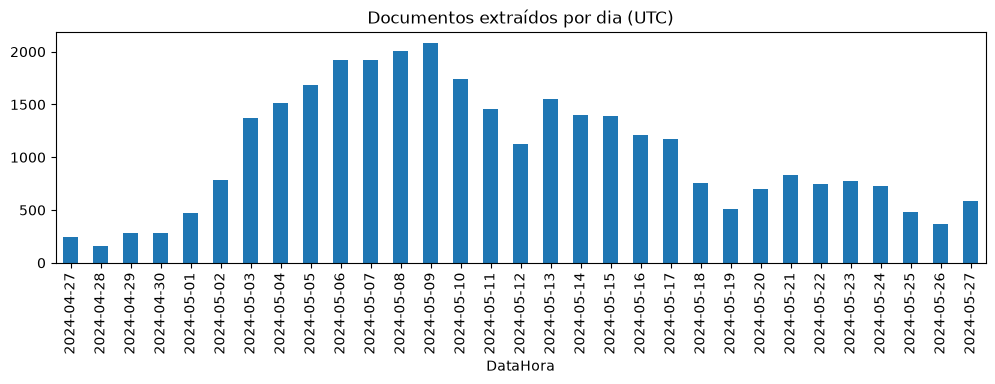

In [11]:
# Volume por dia (UTC): há buracos? o pico está onde esperado?
por_dia = df.groupby(pd.to_datetime(df["DataHora"]).dt.date).size()
por_dia.plot(kind="bar", figsize=(12, 3), title="Documentos extraídos por dia (UTC)");

In [ ]:
# Top 30 veículos: os internacionais aparecem? 
df["Veiculo"].value_counts().head(30)

Veiculo
globo.com                    2547
uol.com.br                   2246
terra.com.br                 1273
correiodopovo.com.br         1225
jornaldebrasilia.com.br       678
ig.com.br                     642
brasil247.com                 563
bemparana.com.br              534
correiobraziliense.com.br     478
estadao.com.br                395
dgabc.com.br                  393
gaz.com.br                    389
ebc.com.br                    385
clicrbs.com.br                380
gazetadopovo.com.br           272
abril.com.br                  246
r7.com                        245
exame.com                     215
correio24horas.com.br         210
jornaldocomercio.com          205
acritica.net                  194
otempo.com.br                 193
cartacapital.com.br           190
acessa.com                    181
diariodepernambuco.com.br     177
infomoney.com.br              160
revistaforum.com.br           158
hojeemdia.com.br              157
180graus.com                  152
progre

In [ ]:
# Amostra 
df[["DataHora", "Veiculo", "URL"]].sample(30, random_state=42)

,DataHora,Veiculo,URL
13899,2024-05-11 22:15:00+00:00,correiobraziliense.com.br,https://www.correiobraziliense.com.br/mundo/20...
27520,2024-05-13 05:45:00+00:00,acritica.net,https://www.acritica.net/editorias/geral/candi...
31720,2024-04-29 14:00:00+00:00,brasil247.com,https://www.brasil247.com:443/economia/igp-m-a...
11487,2024-05-23 21:45:00+00:00,infomoney.com.br,https://www.infomoney.com.br/politica/em-mais-...
7743,2024-05-24 14:15:00+00:00,ambito.com,https://www.ambito.com/economia/automotrices-l...
4706,2024-05-18 05:00:00+00:00,cartacapital.com.br,https://www.cartacapital.com.br/sociedade/lewa...
26791,2024-05-03 16:45:00+00:00,globo.com,https://g1.globo.com/rs/rio-grande-do-sul/noti...
18478,2024-05-08 19:15:00+00:00,terra.com.br,https://www.terra.com.br/noticias/brasil/saque...
2868,2024-05-11 19:30:00+00:00,telemundodenver.com,https://www.telemundodenver.com/noticias/mundo...
24074,2024-05-09 21:45:00+00:00,correiodopovo.com.br,https://www.correiodopovo.com.br/not%C3%ADcias...


In [15]:
import tldextract

df["Veiculo"] = df["Veiculo"].fillna("").str.lower().str.strip()
ext = df["Veiculo"].map(tldextract.extract)
df["tld"] = ext.map(lambda e: e.suffix)
df["domain"] = ext.map(lambda e: f"{e.domain}.{e.suffix}" if e.suffix else e.domain)

df["lang_origem"] = df["TranslationInfo"].str.extract(r"srclc:(\w+)")
df["is_por"] = df["lang_origem"].eq("por")

GENERICOS = {"com", "net", "org", "info", "tv", "co", "io", "news", "online"}
def grupo_prelim(tld):
    if tld == "": return "sem_dominio"
    if tld.endswith("br"): return "tld_br"
    if tld in GENERICOS: return "generico_ambiguo"
    return "tld_estrangeiro"
df["grupo_prelim"] = df["tld"].map(grupo_prelim)

# 1) Visão geral
print(df["grupo_prelim"].value_counts())
print(df["lang_origem"].value_counts(dropna=False).head(10))

# 2) Tabela por domínio
dom = (df.groupby("domain")
         .agg(n=("GKGRECORDID", "size"), pct_por=("is_por", "mean"), tld=("tld", "first"))
         .sort_values("n", ascending=False))

# 3) Candidatos a internacional: domínios com pouco português
cand = dom[dom["pct_por"] < 0.5]
print(f"\nDomínios candidatos a internacionais: {len(cand)} | documentos: {cand['n'].sum():,}")
display(cand.head(40))

# 4) Veículos internacionais conhecidos estão na base?
INTL = (r"reuters|bbc|theguardian|apnews|cnn|nytimes|washingtonpost|aljazeera|dw\.com|france24|"
        r"euronews|elpais|infobae|clarin|lemonde|bloomberg|efe\.com|ft\.com|wsj|skynews|"
        r"abcnews|nbcnews|cbsnews|rfi\.fr|swissinfo|xinhua|cgtn|independent\.co")
display(dom[dom.index.str.contains(INTL)])

# 5) Concentração: quanto os 3 maiores domínios pesam
print(f"\nTop 3 domínios = {dom['n'].head(3).sum()/dom['n'].sum()*100:.1f}% dos documentos")

grupo_prelim
tld_br              15763
generico_ambiguo    11786
tld_estrangeiro      4720
Name: count, dtype: int64
lang_origem
por    21501
spa     5241
NaN     4629
ita      238
zho      142
deu      133
ara       58
fra       39
ukr       35
hin       29
Name: count, dtype: int64

Domínios candidatos a internacionais: 2423 | documentos: 10,715


,n,pct_por,tld
domain,,,
yahoo.com,127,0.00000,com
iheart.com,110,0.00000,com
marketscreener.com,97,0.00000,com
terradaily.com,80,0.00000,com
elpais.com.uy,80,0.00000,com.uy
cadena3.com,77,0.00000,com
prensa-latina.cu,75,0.00000,cu
infobae.com,71,0.00000,com
teleprensa.com,69,0.00000,com


,n,pct_por,tld
domain,,,
dw.com,80,0.550000,com
elpais.com.uy,80,0.000000,com.uy
infobae.com,71,0.000000,com
cnn.com,55,0.000000,com
clarin.com,43,0.000000,com
elpais.cr,42,0.000000,cr
france24.com,35,0.000000,com
euronews.com,29,0.241379,com
elpais.com,27,0.000000,com



Top 3 domínios = 18.8% dos documentos
